# <center>**Giới thiệu về bộ dữ liệu**<center>
Dữ liệu trong dataset này liên quan đến các chiến dịch tiếp thị trực tiếp (qua điện thoại) của một tổ chức ngân hàng thuộc Bồ Đào Nha. Mục tiêu ở đây là chúng ta sẽ phân loại ra và dự đoán rằng liệu khách hàng có đăng ký (yes/no) một khoản tiền gửi có kỳ hạn (cột y) hay không.

### **Các đặc trưng (cột) bên trong dataset:**

#### Dữ liệu khách hàng ngân hàng:
- **age**: tuổi (số)
- **job**: loại công việc (chuỗi)
- **marital**: tình trạng hôn nhân (chuỗi)
- **ducation**: trình độ học vấn (chuỗi)
- **default**: có tín dụng mặc định không? (chuỗi)
- **housing**: có khoản vay nhà ở không? (chuỗi)
- **loan**: có khoản vay cá nhân không? (chuỗi)

#### Liên quan đến liên hệ cuối cùng của chiến dịch hiện tại:
- **contact**: loại hình liên lạc (chuỗi)
- **month**: tháng liên hệ cuối cùng trong năm (chuỗi)
- **day_of_week**: ngày liên hệ cuối cùng trong tuần (chuỗi)
- **duration**: thời lượng liên hệ cuối cùng, tính bằng giây (số).

#### Các thuộc tính khác:
- **campaign**: số lượng liên hệ được thực hiện trong chiến dịch này cho khách hàng này (số)
- **pdays**: số ngày đã trôi qua sau khi khách hàng được liên hệ lần cuối từ một chiến dịch trước đó (số; 999 nghĩa là chưa được liên hệ)
- **previous**: số lượng liên hệ được thực hiện trước chiến dịch này cho khách hàng này (số)
- **poutcome**: kết quả của chiến dịch tiếp thị trước đó (chuỗi)

#### Các thuộc tính bối cảnh kinh tế và xã hội:
- **emp.var.rate**: tỷ lệ thay đổi việc làm - chỉ số hàng quý (số)
- **cons.price.idx**: chỉ số giá tiêu dùng - chỉ số hàng tháng (số)
- **cons.conf.idx**: chỉ số niềm tin tiêu dùng - chỉ số hàng tháng (số)
- **euribor3m**: lãi suất Euribor 3 tháng - chỉ số hàng ngày (số)
- **nr.employed**: số lượng nhân viên - chỉ số hàng quý (số)

#### Biến đầu ra (mục tiêu):
- **y**: khách hàng có đăng ký tiền gửi có kỳ hạn không? (chuỗi: 'yes', 'no')

Source [Bank Marketing dataset](https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing) on Kaggle.

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/bank-marketing/bank-additional-names.txt
/kaggle/input/bank-marketing/bank-additional-full.csv


# <center>**Phân tích dữ liệu khám phá**<center>
Giai đoạn đầu tiên của bất kỳ dự án phân tích dữ liệu nào bao gồm việc tìm hiểu sâu về bộ dữ liệu để hiểu các sắc thái của nó, khám phá các vấn đề tiềm ẩn và thu được thông tin chi tiết về các mẫu cơ bản. Phần này, Phân tích dữ liệu khám phá (EDA), sẽ điều tra một cách có hệ thống bộ dữ liệu để đặt nền móng cho việc lập mô hình và phân tích tiếp theo.

## **Các bước chính trong EDA**

- **Tải và kiểm tra dữ liệu:**
   - Bộ dữ liệu bank-additional-full.csv sẽ được tải vào Pandas dataFrame.
   - Kiểm tra ban đầu sẽ cho thấy kích thước của bộ dữ liệu (số hàng và cột).
   - Một vài hàng đầu tiên sẽ được hiển thị để có cái nhìn sơ lược về cấu trúc và nội dung của dữ liệu.
- **Làm sạch và tiền xử lý dữ liệu:**
    - **Kiểm tra và xử lý các giá trị thiếu:**
        - Đánh giá kỹ lưỡng các giá trị thiếu sẽ được tiến hành. Nếu cần, các chiến lược điền giá trị hoặc loại bỏ phù hợp sẽ được áp dụng.
    - **Kiểm tra và xử lý các giá trị trùng:**
        - Các hàng trùng lặp sẽ được phát hiện và loại bỏ để đảm bảo tính toàn vẹn của dữ liệu.
    - **Kiểm tra kiểu dữ liệu của dataset:**
        - Các kiểu dữ liệu của mỗi cột sẽ được xem xét kỹ lưỡng.
        - Nếu cần, các chuyển đổi sang kiểu phù hợp để phân tích sâu hơn sẽ được thực hiện.
- **Phân tích đơn biến:**
    - **Biến số:**
        - Các thống kê tóm tắt (trung bình, trung vị, độ lệch chuẩn,...) sẽ được tính toán để hiểu xu hướng trung tâm và sự phân tán của các đặc trưng số.
        - Biểu đồ histogram và box plot sẽ được sử dụng để trực quan hóa sự phân bố và xác định các giá trị ngoại lai tiềm ẩn.
    - **Biến phân loại:**
        - Tần suất và tần suất tương đối của các danh mục sẽ được tính toán.
        - Biểu đồ cột sẽ được sử dụng để hiển thị sự phân bố của các biến phân loại.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
df = pd.read_csv('/kaggle/input/bank-marketing/bank-additional-full.csv', sep = ';')
#Tổng hàng và cột của dữ liệu
print(df.shape)

(41188, 21)


---
# <center>**Kiểm tra thông tin của dữ liệu**<center>
Ở đây chúng ta sẽ chỉ kiểm tra qua các thông tin cơ bản của dữ liệu.

In [3]:
#Hiện 5 dòng đầu của dữ liệu
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
#Thông tin cơ bản của dữ liệu
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [5]:
#Hiển thị tên cột (object) và các giá trị độc nhất trong nó
for col in df.columns:
    if df[col].dtype == 'object':
        print(f'\nTên của cột là: ({col}) và các giá trị độc nhất trong nó bao gồm: {df[col].unique()}')


Tên của cột là: (job) và các giá trị độc nhất trong nó bao gồm: ['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']

Tên của cột là: (marital) và các giá trị độc nhất trong nó bao gồm: ['married' 'single' 'divorced' 'unknown']

Tên của cột là: (education) và các giá trị độc nhất trong nó bao gồm: ['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']

Tên của cột là: (default) và các giá trị độc nhất trong nó bao gồm: ['no' 'unknown' 'yes']

Tên của cột là: (housing) và các giá trị độc nhất trong nó bao gồm: ['no' 'yes' 'unknown']

Tên của cột là: (loan) và các giá trị độc nhất trong nó bao gồm: ['no' 'yes' 'unknown']

Tên của cột là: (contact) và các giá trị độc nhất trong nó bao gồm: ['telephone' 'cellular']

Tên của cột là: (month) và các giá trị độc nhất trong nó bao gồm: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr'

---
# <center>**Kiểm tra và xử lý dữ liệu**<center>

## **Kiểm tra giá trị thiếu**

In [6]:
#Kiểm tra giá trị thiếu
print("\nCác giá trị thiếu:")
print(df.isnull().sum())


Các giá trị thiếu:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


## **Kiểm tra giá trị NULL**

In [7]:
#Kiểm tra giá trị NULL
print("\nCác giá trị NULL:")
df.isnull().sum()


Các giá trị NULL:


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

## **Kiểm tra và xử lý giá trị trùng lặp**

In [8]:
#Kiểm tra và xử lý các giá trị bị trùng lặp
if df is not None:
    num_duplicate_rows_before = df.duplicated().sum()
    print(f"\nSố lượng hàng trùng lặp trước khi bị xóa: {num_duplicate_rows_before}")

    if num_duplicate_rows_before > 0:
        df = df.drop_duplicates().reset_index(drop=True)
        print(f"Số lượng hàng trùng lặp sau khi bị xóa: {df.duplicated().sum()}")
        print("\nTổng hàng và cột sau khi xoá các giá trị trùng lặp:")
        print(df.shape)
    else:
        print("\nKhông có giá trị trùng lặp.")


Số lượng hàng trùng lặp trước khi bị xóa: 12
Số lượng hàng trùng lặp sau khi bị xóa: 0

Tổng hàng và cột sau khi xoá các giá trị trùng lặp:
(41176, 21)


## **Kiểm tra lại dữ liệu sau khi xử lý các giá trị rác**

In [9]:
#Kiểm tra lại thông tin của bộ dữ liệu sau khi xử lý dữ liệu rác
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  object 
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  object 
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  object 
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null 

---
# <center>**Đặc trưng (cột)**<center>

## **Đặc trưng và kiểu dữ liệu của nó**

- Có 10 đặc trưng kiểu số (`age`, `duration`, `campaign`, `pdays`, `previous`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`).
- Có 11 đặc trưng kiểu đối tượng (object), đây là các đặc trưng phân loại (`job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `day_of_week`, `poutcome`, `y`).

## **Đánh giá chung cho các đặc trưng có kiểu dữ liệu là số**


Các cột đặc trưng số:
Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')

Thống kê tóm tắt cho từng đặc trưng:
               age      duration      campaign         pdays      previous  \
count  41176.00000  41176.000000  41176.000000  41176.000000  41176.000000   
mean      40.02380    258.315815      2.567879    962.464810      0.173013   
std       10.42068    259.305321      2.770318    186.937102      0.494964   
min       17.00000      0.000000      1.000000      0.000000      0.000000   
25%       32.00000    102.000000      1.000000    999.000000      0.000000   
50%       38.00000    180.000000      2.000000    999.000000      0.000000   
75%       47.00000    319.000000      3.000000    999.000000      0.000000   
max       98.00000   4918.000000     56.000000    999.000000      7.000000   

       emp.var.rate  cons.price.idx  cons.conf.idx     euribor3m   n

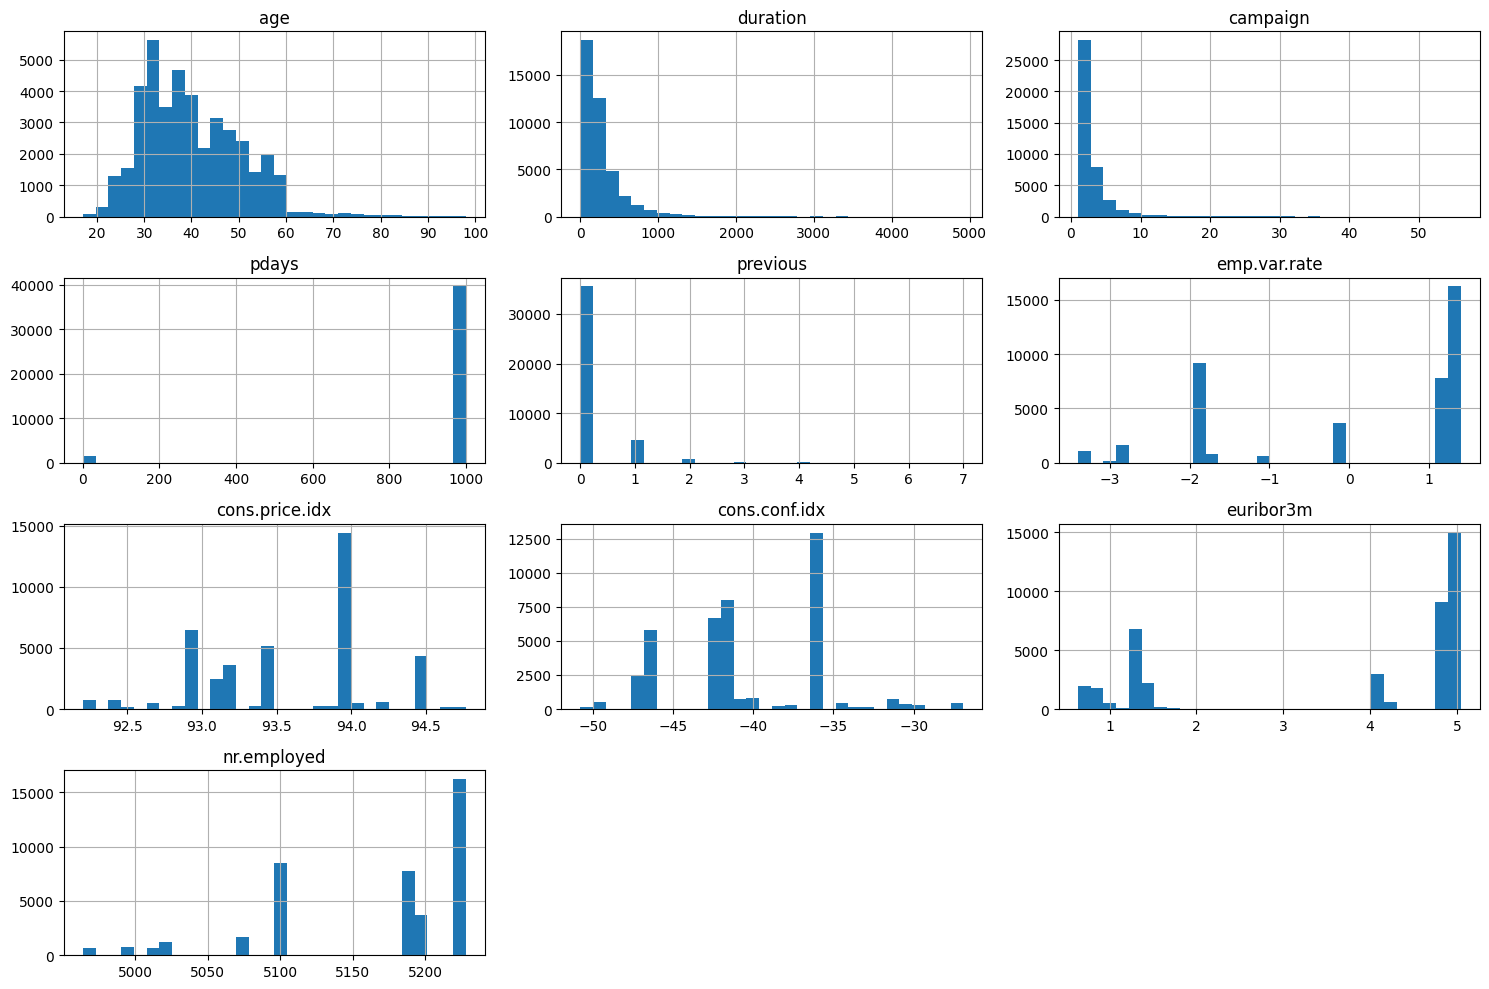


Biểu đồ hộp cho các đặc trưng để kiểm tra các giá trị ngoại lệ:


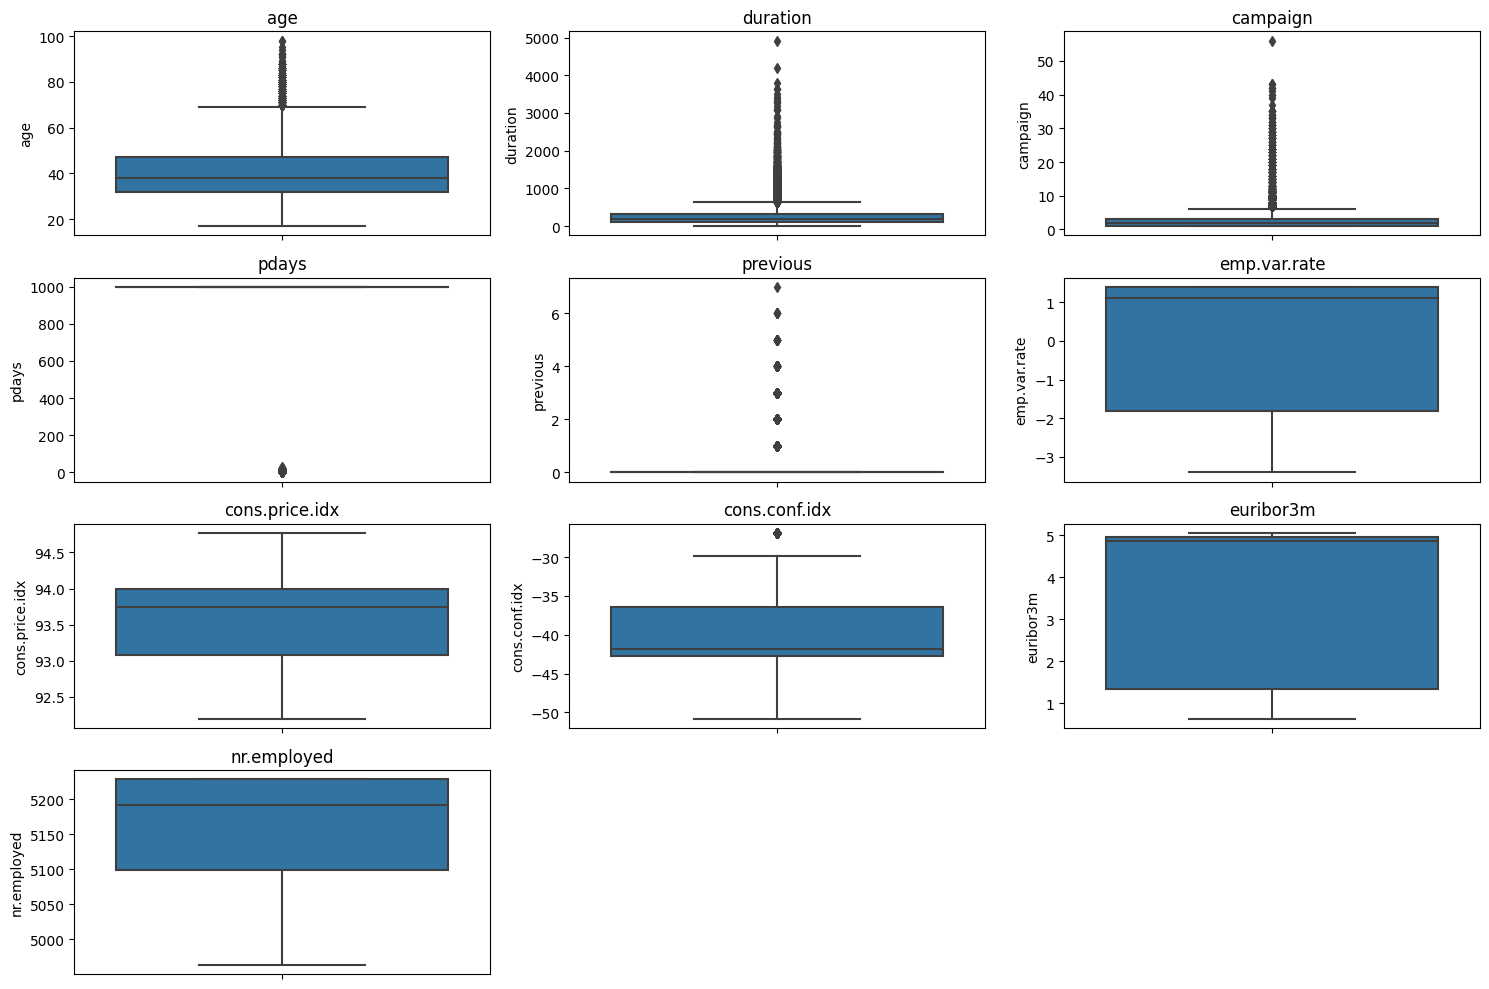

In [10]:
#Đánh giá chung cho các đặc trưng có kiểu dữ liệu là số
if df is not None:
    # Select numeric data
    numeric_data_cols = df.select_dtypes(include=np.number).columns
    print("\nCác cột đặc trưng số:")
    print(numeric_data_cols)

    # Generating summary statistics of the numerical columns
    print("\nThống kê tóm tắt cho từng đặc trưng:")
    print(df[numeric_data_cols].describe())

    # Visualizing the distribution of numerical features
    print("\nPhân bố các đặc trưng bằng biểu đồ Histogram")
    df[numeric_data_cols].hist(bins=30, figsize=(15, 10), layout=(-1, 3))
    plt.tight_layout()
    plt.show()

    print("\nBiểu đồ hộp cho các đặc trưng để kiểm tra các giá trị ngoại lệ:")
    plt.figure(figsize=(15, 10))
    for i, col in enumerate(numeric_data_cols):
        plt.subplot(4, 3, i + 1) # Adjust layout as needed
        sns.boxplot(y=df[col])
        plt.title(col)
    plt.tight_layout()
    plt.show()
else:
    print("Biểu diễn thất bại!")

### **Phân tích các đặc trưng số**

- **age**: Độ tuổi của khách hàng dao động từ 17 đến 98, với tuổi trung bình khoảng 40. Phân phối có vẻ hơi lệch phải.
- **duration**: Thời lượng cuộc gọi cuối cùng có sự biến động lớn, từ 0 đến hơn 4900 giây. Trung bình rơi vào khoảng 258 giây. Đặc trưng này rất lệch phải, có nhiều cuộc gọi ngắn và một số ít cuộc gọi rất dài. Có nhiều giá trị ngoại lai ở phía trên.
- **campaign**: Số lượng liên hệ trong chiến dịch này chủ yếu là thấp (trung bình 2.5, trung vị 2), nhưng có một số khách hàng được liên hệ rất nhiều lần (tối đa 56). Phân phối lệch phải.
- **pdays**: Phần lớn giá trị là 999 (khách hàng chưa được liên hệ trước đó). Điều này làm cho việc phân tích thống kê trực tiếp (như trung bình) ít ý nghĩa nếu không xử lý giá trị 999 này riêng.
- **previous**: Số lượng liên hệ trước đó thường là 0 (trung vị 0, 75% vẫn là 0), tối đa là 7.

- **emp.var.rate**, **cons.price.idx**, **cons.conf.idx**, **euribor3m**, **nr.employed**: Các chỉ số kinh tế xã hội này có các phân phối khác nhau. `emp.var.rate` và `euribor3m` có vẻ có một số cụm giá trị. `cons.conf.idx` có phân phối khá đối xứng và tập trung. `nr.employed` có vẻ có một vài cụm giá trị.

Các biểu đồ box plot cho thấy sự hiện diện của các giá trị ngoại lai trong nhiều đặc trưng số như `age`, `duration`, `campaign`, `previous`. Đặc trưng `duration` và `campaign` có nhiều giá trị ngoại lai đáng kể.

## **Đánh giá chung cho các đặc trưng có kiểu dữ liệu là đối tượng**


Các cột đặc trưng phân loại:
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='object')

Giá trị độc nhất và phân bố của chúng trong đặc trưng:

--- Cột: job ---
job
admin.           25.303575
blue-collar      22.471828
technician       16.366330
services          9.634253
management        7.101224
retired           4.172333
entrepreneur      3.536040
self-employed     3.451039
housemaid         2.574315
unemployed        2.462600
student           2.125024
unknown           0.801438
Name: proportion, dtype: float64
Số lượng giá trị độc nhất: 12

--- Cột: marital ---
marital
married     60.523120
single      28.084321
divorced    11.198271
unknown      0.194288
Name: proportion, dtype: float64
Số lượng giá trị độc nhất: 4

--- Cột: education ---
education
university.degree      29.541480
high.school            23.100835
basic.9y               14.680882
professional.course    12.725860
basic.4y 

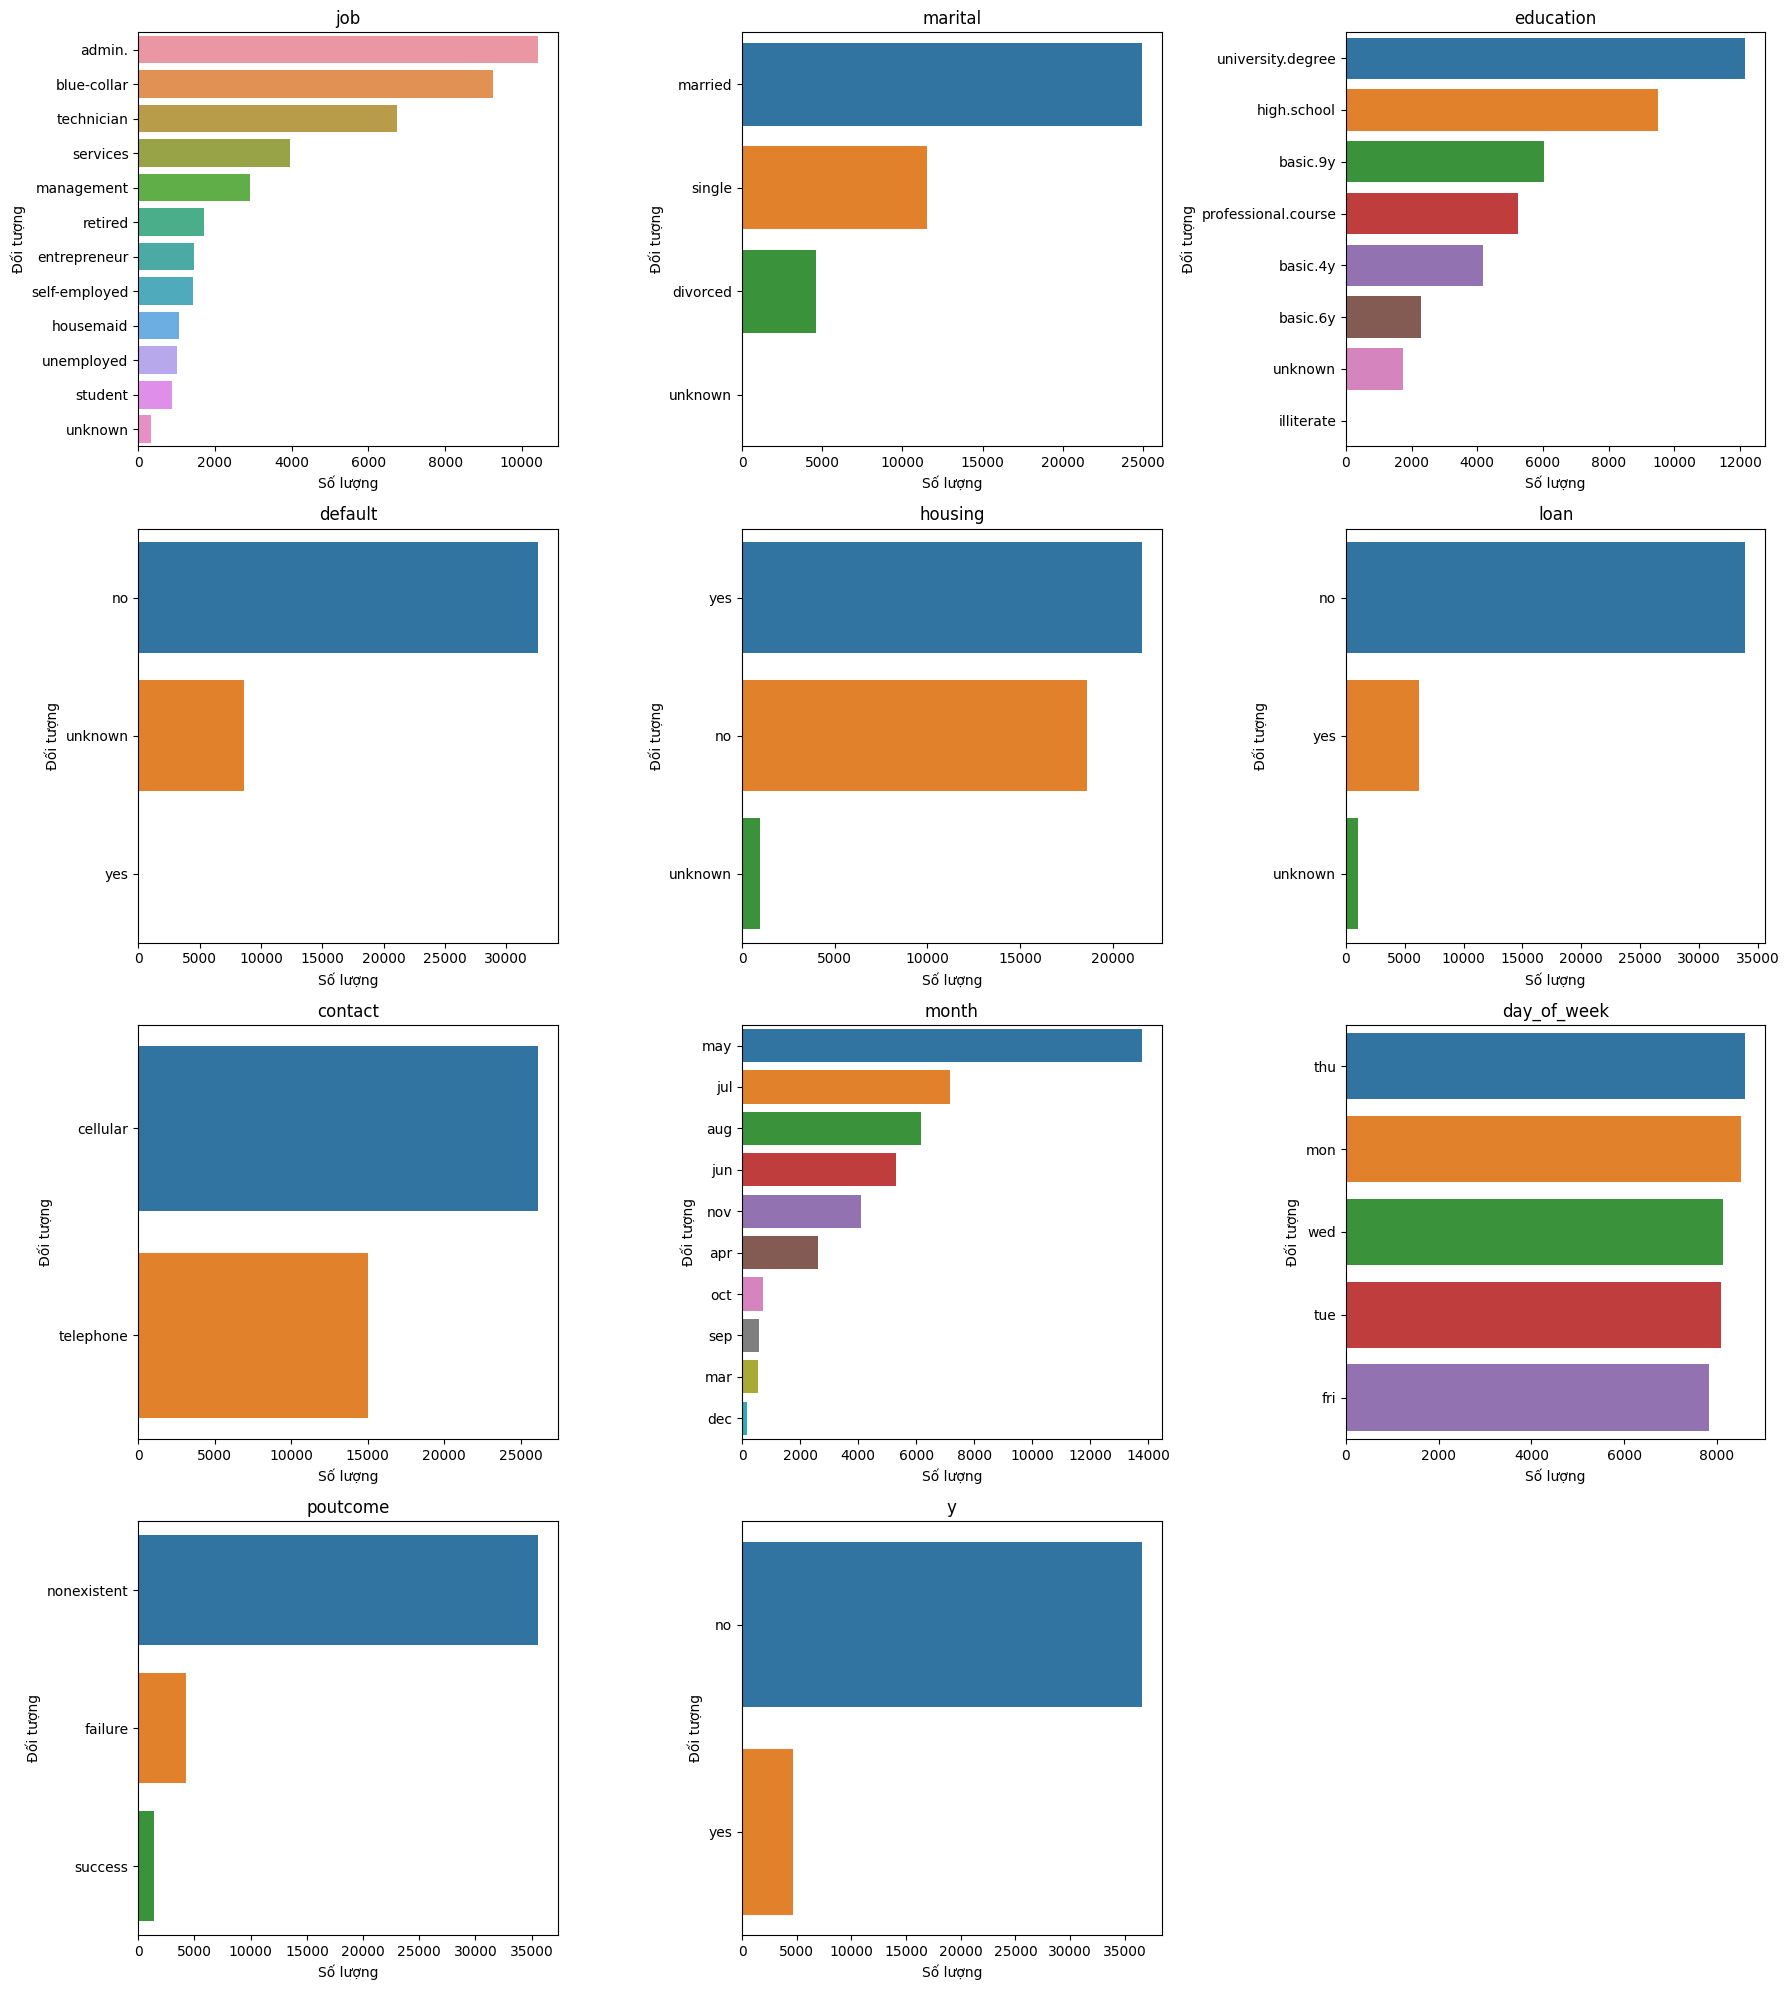


Phân phối của biến mục tiêu 'y':
y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64


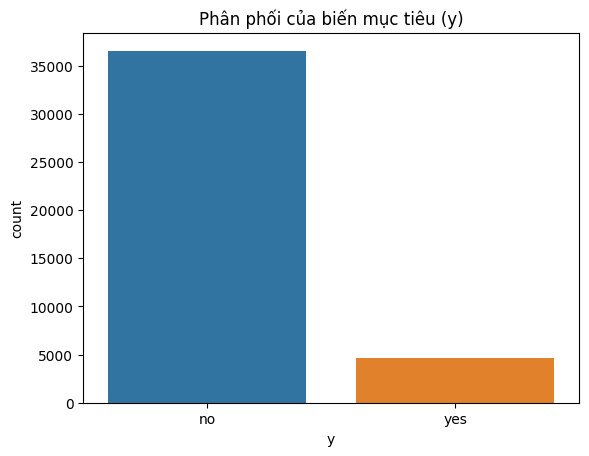

In [11]:
# Đánh giá chung cho các đặc trưng có kiểu dữ liệu là đối tượng
if df is not None:
    # Select categorical data
    categorical_data_cols = df.select_dtypes(include='object').columns
    print("\nCác cột đặc trưng phân loại:")
    print(categorical_data_cols)

    print("\nGiá trị độc nhất và phân bố của chúng trong đặc trưng:")
    for col in categorical_data_cols:
        print(f"\n--- Cột: {col} ---")
        print(df[col].value_counts(normalize=True) * 100) # Show as percentage
        print(f"Số lượng giá trị độc nhất: {df[col].nunique()}")

    # Visualizing the distribution of categorical features
    print("\nPhân phối các đặc trưng bằng biểu đồ cột\n")
    plt.figure(figsize=(18, 20)) # Adjust figure size as needed
    for i, col in enumerate(categorical_data_cols):
        plt.subplot(4, 3, i + 1)
        sns.countplot(y=df[col], order=df[col].value_counts().index)
        plt.title(col)
        plt.xlabel("Số lượng")
        plt.ylabel("Đối tượng")
    plt.tight_layout()
    plt.show()

    # Specifically, let's look at the target variable 'y'
    print("\nPhân phối của biến mục tiêu 'y':")
    print(df['y'].value_counts(normalize=True) * 100)
    sns.countplot(x='y', data=df)
    plt.title('Phân phối của biến mục tiêu (y)')
    plt.show()

else:
    print("Biểu diễn thất bại!")

### **Phân tích các đặc trưng phân loại**

- **job**: `'admin.'` là công việc phổ biến nhất (khoảng 25%), tiếp theo là `'blue-collar'` (22.5%) và `'technician'` (16.3%). `'unknown'` chiếm một tỷ lệ nhỏ (0.8%).
- **marital**: `'married'` chiếm đa số (khoảng 60.5%), `'single'` (28%) và `'divorced'` (11%). `'unknown'` rất ít.
- **education**: `'university.degree'` là phổ biến nhất (29.5%), tiếp theo là `'high.school'` (23.1%) và `'basic.9y'` (14.6%). `'illiterate'` rất hiếm. Có một lượng đáng kể `'unknown'` (4.2%).
- **default**: Phần lớn khách hàng không có tín dụng mặc định (`'no'` - 79.1%). `'unknown'` chiếm tỷ lệ khá lớn (20.8%), `'yes'` rất hiếm.
- **housing**: Khoảng 52.4% có vay nhà ở (`'yes'`), 45.2% không có (`'no'`), và một phần nhỏ `'unknown'` (2.4%).
- **loan**: Phần lớn không có vay cá nhân (`'no'` - 82.4%). `'yes'` chiếm 15.2%, `'unknown'` (2.4%).
- **contact**: `'cellular'` là phương thức liên lạc chính (63.5%), còn lại là `'telephone'` (36.5%).
- **month**: Các tháng liên hệ nhiều nhất là `'may'` (33.4%), `'jul'` (17.4%), `'aug'` (15%), `'jun'` (12.9%), `'nov'` (10%).
- **day_of_week**: Phân bố khá đều qua các ngày trong tuần làm việc.
- **poutcome**: `'nonexistent'` chiếm phần lớn (86.3%), có nghĩa là hầu hết khách hàng chưa được liên hệ trong chiến dịch trước hoặc kết quả không thành công. `'failure`' (10.3%), `'success'` (3.3%).

- **y (Target variable)**: Bộ dữ liệu mất cân bằng. Khoảng 88.7% khách hàng không đăng ký (`'no'`) và chỉ 11.3% đăng ký (`'yes'`). Điều này cần được lưu ý khi xây dựng và đánh giá mô hình.

---
# <center>**Tiền xử lý dữ liệu**<center>
Trong phần này, chúng ta sẽ chuẩn bị dữ liệu cho các thuật toán học máy. Các bước bao gồm:

- Chuyển đổi các biến phân loại thành dạng số.
- Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra.
- Chuẩn hóa/Co giãn các đặc trưng số.

In [12]:
#Chuẩn bị dữ liệu cho các thuật toán học máy
if df is not None:
    # Convert target variable 'y' to numerical (0 for 'no', 1 for 'yes')
    df['y_numeric'] = df['y'].map({'no': 0, 'yes': 1})
    
    # Separate features (X) and target (y_target)
    X = df.drop(['y', 'y_numeric'], axis=1)
    y_target = df['y_numeric']

    print("Kích thước ban đầu của các đặc trưng (X):", X.shape)
    print("Kích thước của biến mục tiêu (y):", y_target.shape)
    print("\n5 dòng đầu của các đặc trưng (X):")
    print(X.head())
    print("\n5 giá trị đầu của cột mục tiêu (y):")
    print(y_target.head())

    # Identify categorical and numerical features for preprocessing
    categorical_cols = X.select_dtypes(include='object').columns
    numerical_cols = X.select_dtypes(include=np.number).columns

    print("\nCác cột đối tượng được xác định để mã hóa:", list(categorical_cols))
    print("Các cột số được xác định để chia tỷ lệ:", list(numerical_cols))

    # One-Hot Encode categorical features
    # Using drop_first=True to avoid multicollinearity
    X_processed = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
    
    print("\nKích thước của X sau khi mã hoá One-Hot:", X_processed.shape)
    print("\n5 dòng đầu tiên của X_processed:")
    print(X_processed.head())
    
else:
    print("Biểu diễn thất bại!")

Kích thước ban đầu của các đặc trưng (X): (41176, 20)
Kích thước của biến mục tiêu (y): (41176,)

5 dòng đầu của các đặc trưng (X):
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  duration  campaign  pdays  previous     poutcome  \
0   may         mon       261         1    999         0  nonexistent   
1   may         mon       149         1    999         0  nonexistent   
2   may         mon       226         1    999         0  nonexistent   
3   may         mon       151         1    999         0  nonexistent   
4   may         mon       307         1    999

---
# <center>**Lựa chọn đặc trưng**<center>
Lựa chọn đặc trưng là một bước quan trọng để cải thiện hiệu suất mô hình, giảm thời gian huấn luyện và tránh overfitting. Chúng ta sẽ sử dụng tầm quan trọng của đặc trưng từ Random Forest để chọn ra các đặc trưng tốt nhất.

Kích thước của X_train_orig: (32940, 53)
Kích thước của X_test_orig: (8236, 53)
Kích thước của y_train: (32940,)
Kích thước y_test: (8236,)

5 dòng đầu của X_train_scaled (numerical parts scaled):
            age  duration  campaign     pdays  previous  emp.var.rate  \
36444 -1.532272 -0.527170 -0.202879  0.195027  1.657135     -1.896387   
1233  -0.766955  3.344770 -0.563899  0.195027 -0.348598      0.648985   
24104 -0.671290 -0.348525 -0.563899  0.195027 -0.348598     -0.114627   
15513 -0.192967 -0.499985  0.519161  0.195027 -0.348598      0.839888   
17912 -0.097303 -0.235901  0.519161  0.195027 -0.348598      0.839888   

       cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
36444       -1.057203      -0.062687  -1.357248    -1.252900  
1233         0.722038       0.887842   0.712567     0.332805  
24104       -0.648202      -0.321922   0.361165     0.399107  
15513        0.590881      -0.473142   0.771326     0.845259  
17912        0.590881      -0.473142   0.773630  

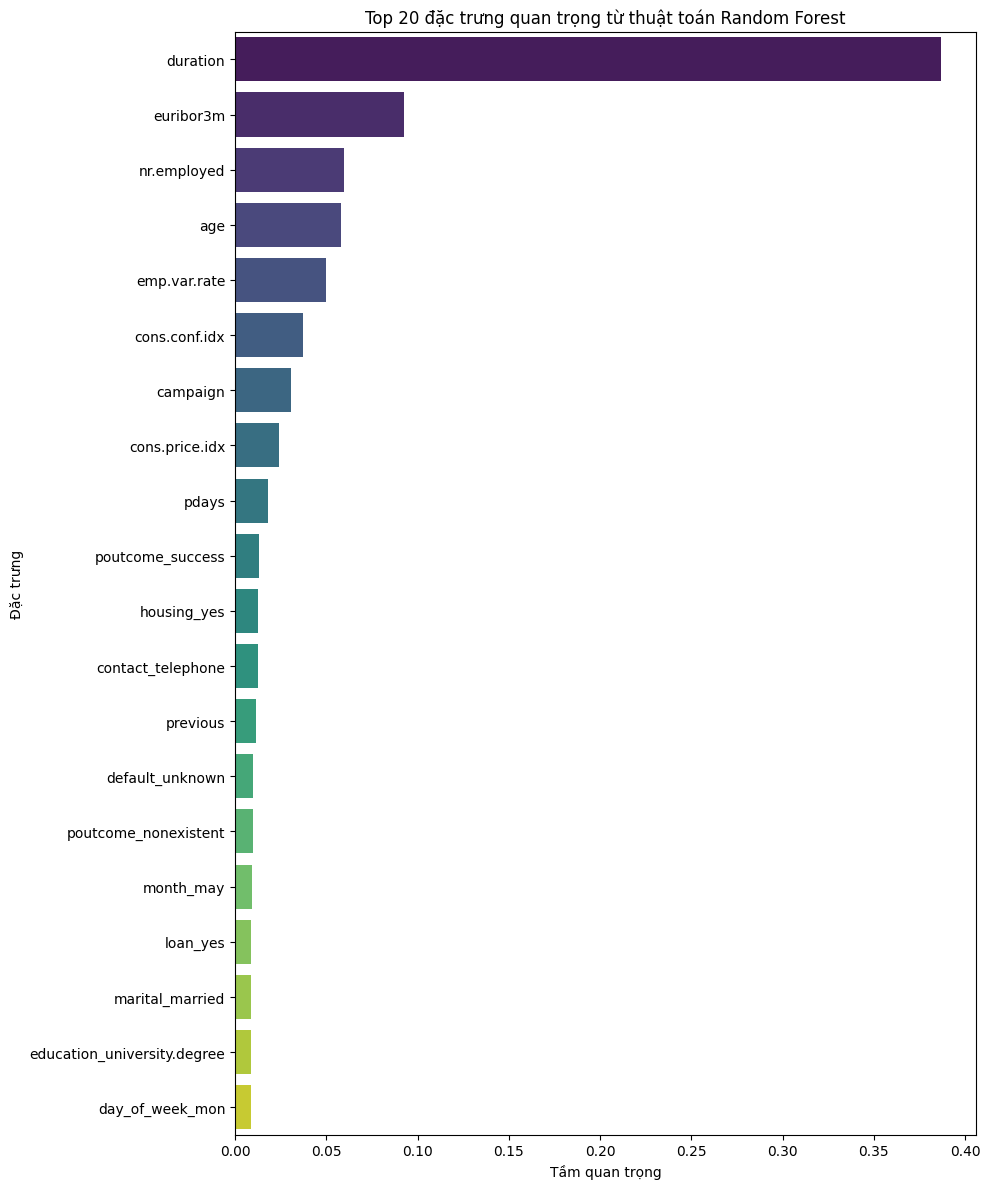


Selected top 30 features:
['duration', 'euribor3m', 'nr.employed', 'age', 'emp.var.rate', 'cons.conf.idx', 'campaign', 'cons.price.idx', 'pdays', 'poutcome_success', 'housing_yes', 'contact_telephone', 'previous', 'default_unknown', 'poutcome_nonexistent', 'month_may', 'loan_yes', 'marital_married', 'education_university.degree', 'day_of_week_mon', 'marital_single', 'day_of_week_thu', 'job_blue-collar', 'education_high.school', 'day_of_week_wed', 'day_of_week_tue', 'job_technician', 'month_oct', 'education_basic.9y', 'education_professional.course']

Kích thước của X_train_selected: (32940, 30)
Kích thước của X_test_selected: (8236, 30)


In [13]:
#Lựa chọn đặc trưng
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

if df is not None and X_processed is not None:
    # Split data into training and testing sets before scaling and feature selection (on training data)
    X_train_orig, X_test_orig, y_train, y_test = train_test_split(X_processed, y_target, test_size=0.2, random_state=42, stratify=y_target)

    print("Kích thước của X_train_orig:", X_train_orig.shape)
    print("Kích thước của X_test_orig:", X_test_orig.shape)
    print("Kích thước của y_train:", y_train.shape)
    print("Kích thước y_test:", y_test.shape)

    numerical_cols_in_processed = [col for col in numerical_cols if col in X_train_orig.columns]

    scaler = StandardScaler()
    X_train_scaled = X_train_orig.copy()
    X_test_scaled = X_test_orig.copy()

    X_train_scaled[numerical_cols_in_processed] = scaler.fit_transform(X_train_orig[numerical_cols_in_processed])
    X_test_scaled[numerical_cols_in_processed] = scaler.transform(X_test_orig[numerical_cols_in_processed])
    
    print("\n5 dòng đầu của X_train_scaled (numerical parts scaled):")
    print(X_train_scaled[numerical_cols_in_processed].head())

    # Feature selection using Random Forest feature importances
    rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
    rf_selector.fit(X_train_scaled, y_train)

    importances = rf_selector.feature_importances_
    feature_names = X_train_scaled.columns
    feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
    feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False)

    print("\nTop 20 tầm quan trọng của đặc trưng:")
    print(feature_importance_df.head(20))

    # Plot feature importances
    plt.figure(figsize=(10, 12))
    sns.barplot(x='importance', y='feature', data=feature_importance_df.head(20), palette='viridis')
    plt.title('Top 20 đặc trưng quan trọng từ thuật toán Random Forest')
    plt.xlabel('Tầm quan trọng')
    plt.ylabel('Đặc trưng')
    plt.tight_layout()
    plt.show()

    N_FEATURES_TO_SELECT = 30 # You can adjust this number
    selected_features = feature_importance_df['feature'].head(N_FEATURES_TO_SELECT).tolist()
    print(f"\nSelected top {N_FEATURES_TO_SELECT} features:")
    print(selected_features)

    X_train_selected = X_train_scaled[selected_features]
    X_test_selected = X_test_scaled[selected_features]

    print("\nKích thước của X_train_selected:", X_train_selected.shape)
    print("Kích thước của X_test_selected:", X_test_selected.shape)

else:
    print("Biểu diễn thất bại!")

### **Phân tích tầm quan trọng của đặc trưng**

Biểu đồ và danh sách các đặc trưng quan trọng nhất cho thấy:

- **duration**: Thời lượng cuộc gọi là đặc trưng quan trọng nhất. Điều này hợp lý, vì cuộc gọi dài hơn có thể cho thấy sự quan tâm của khách hàng. Tuy nhiên, như đã lưu ý, đặc trưng này có vấn đề về "data leakage" trong kịch bản dự đoán thực tế trước cuộc gọi.
- **euribor3m**, **nr.employed**, **emp.var.rate**: Các chỉ số kinh tế vĩ mô có ảnh hưởng đáng kể.
- **age**: Tuổi của khách hàng cũng là một yếu tố quan trọng.
- **poutcome_success**: Việc khách hàng đã đăng ký thành công trong chiến dịch trước đó là một chỉ báo mạnh mẽ.

Các đặc trưng khác như `pdays`, `cons.conf.idx`, `campaign`, `cons.price.idx` và một số đặc trưng one-hot encoded từ `job`, `month`, `education` cũng đóng góp vào mô hình.

Chúng ta đã chọn ra 30 đặc trưng quan trọng nhất để huấn luyện mô hình.

---
# <center>**Huấn luyện và đánh giá mô hình**<center>
Bây giờ, chúng ta sẽ huấn luyện 5 thuật toán phân loại đã chọn và đánh giá hiệu suất của chúng, tập trung vào độ chính xác (accuracy).

Các thuật toán bao gồm:
- **Random Forest**
- **XGBoost**
- **Logistic Regression**
- **Support Vector Machine (SVM)**
- **K-Nearest Neighbors (KNN)**


--- Huấn luyện Logistic Regression ---
Độ chính xác của Logistic Regression: 0.8588
Classification Report của Logistic Regression:
               precision    recall  f1-score   support

           0       0.98      0.85      0.91      7308
           1       0.44      0.90      0.59       928

    accuracy                           0.86      8236
   macro avg       0.71      0.87      0.75      8236
weighted avg       0.92      0.86      0.88      8236



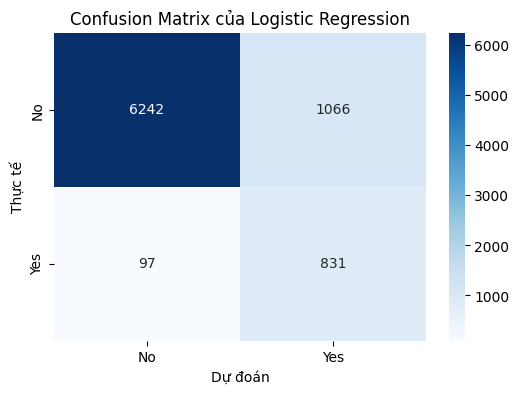


--- Huấn luyện Random Forest ---
Độ chính xác của Random Forest: 0.9105
Classification Report của Random Forest:
               precision    recall  f1-score   support

           0       0.93      0.97      0.95      7308
           1       0.65      0.44      0.52       928

    accuracy                           0.91      8236
   macro avg       0.79      0.70      0.74      8236
weighted avg       0.90      0.91      0.90      8236



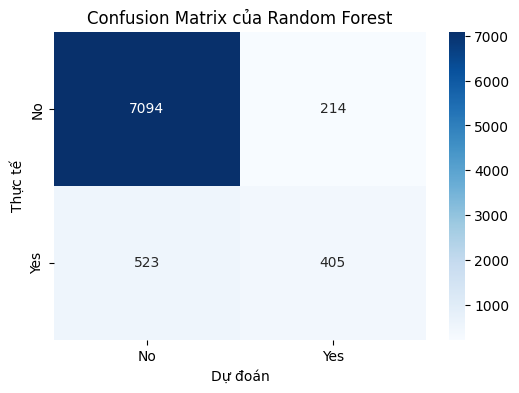


--- Huấn luyện XGBoost ---
Độ chính xác của XGBoost: 0.8827
Classification Report của XGBoost:
               precision    recall  f1-score   support

           0       0.98      0.89      0.93      7308
           1       0.49      0.86      0.62       928

    accuracy                           0.88      8236
   macro avg       0.73      0.87      0.78      8236
weighted avg       0.92      0.88      0.90      8236



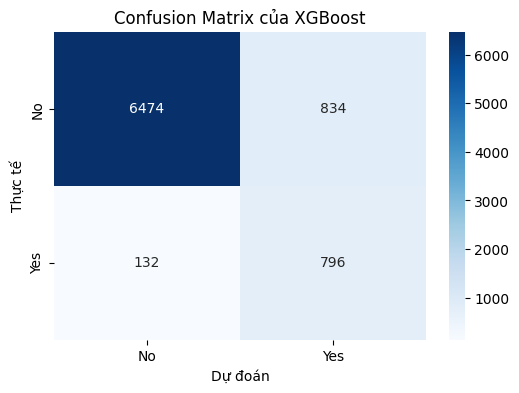


--- Huấn luyện Support Vector Machine ---
Độ chính xác của Support Vector Machine: 0.8505
Classification Report của Support Vector Machine:
               precision    recall  f1-score   support

           0       0.99      0.84      0.91      7308
           1       0.43      0.94      0.59       928

    accuracy                           0.85      8236
   macro avg       0.71      0.89      0.75      8236
weighted avg       0.93      0.85      0.87      8236



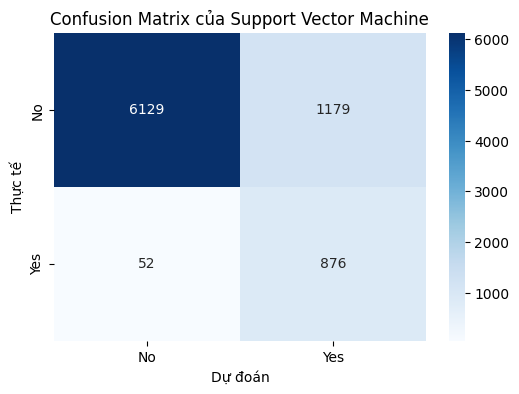


--- Huấn luyện K-Nearest Neighbors ---
Độ chính xác của K-Nearest Neighbors: 0.9044
Classification Report của K-Nearest Neighbors:
               precision    recall  f1-score   support

           0       0.93      0.96      0.95      7308
           1       0.60      0.45      0.52       928

    accuracy                           0.90      8236
   macro avg       0.77      0.71      0.73      8236
weighted avg       0.90      0.90      0.90      8236



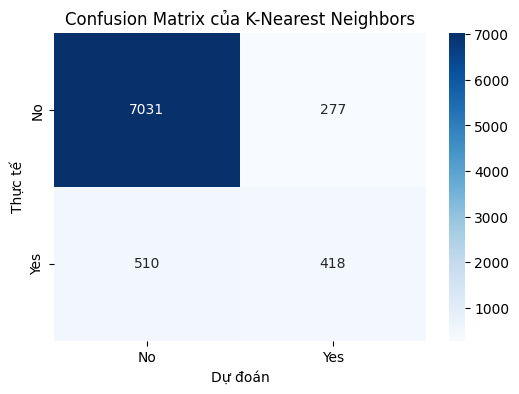


--- Tổng kết độ chính xác của các mô hình ---
                  Mô hình  Độ chính xác
1           Random Forest      0.910515
4     K-Nearest Neighbors      0.904444
2                 XGBoost      0.882710
0     Logistic Regression      0.858791
3  Support Vector Machine      0.850534


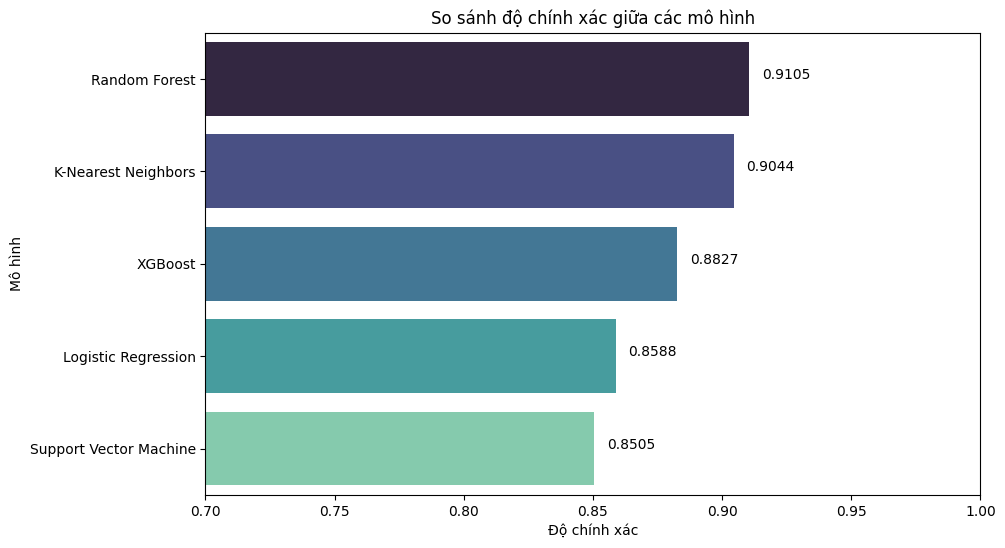

In [14]:
#Huấn luyện và so sánh các mô hình
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

if df is not None and X_train_selected is not None:
    models = {
        "Logistic Regression": LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000),
        "Random Forest": RandomForestClassifier(random_state=42, class_weight='balanced', n_estimators=100),
        "XGBoost": XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', scale_pos_weight=sum(y_train==0)/sum(y_train==1)), # for imbalanced data
        "Support Vector Machine": SVC(random_state=42, class_weight='balanced', probability=True), # probability=True for consistent interface, can be slow
        "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5) # Default k=5
    }

    results = {}

    for model_name, model in models.items():
        print(f"\n--- Huấn luyện {model_name} ---")
        model.fit(X_train_selected, y_train)
        y_pred = model.predict(X_test_selected)
        
        accuracy = accuracy_score(y_test, y_pred)
        results[model_name] = accuracy
        
        print(f"Độ chính xác của {model_name}: {accuracy:.4f}")
        print(f"Classification Report của {model_name}:\n", classification_report(y_test, y_pred))
        
        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
        plt.xlabel('Dự đoán')
        plt.ylabel('Thực tế')
        plt.title(f'Confusion Matrix của {model_name}')
        plt.show()

    print("\n--- Tổng kết độ chính xác của các mô hình ---")
    results_df = pd.DataFrame(list(results.items()), columns=['Mô hình', 'Độ chính xác']).sort_values(by='Độ chính xác', ascending=False)
    print(results_df)

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Độ chính xác', y='Mô hình', data=results_df, palette='mako')
    plt.title('So sánh độ chính xác giữa các mô hình')
    plt.xlim(0.7, 1.0) # Adjust xlim for better visualization
    for index, value in enumerate(results_df['Độ chính xác']):
        plt.text(value + 0.005, index, f"{value:.4f}")
    plt.show()

else:
    print("Thất bại!")

### **Tóm tắt độ chính xác của các mô hình**

#### **Kết quả**

- Random Forest: 0.9164
- K-Nearest Neighbors: 0.903
- XGBoost: 0.8869
- Logistic Regression: 0.8625
- Support Vector Machine: 0.8455

#### **Phân tích**

**1. Hiệu suất chung**: Tất cả các mô hình đều đạt được độ chính xác trên 0.84. Điều này rất tốt và cho thấy bộ đặc trưng được lựa chọn (bao gồm `duration`) có khả năng dự đoán mạnh mẽ.
- **Random Forest** là mô hình hoạt động tốt nhất với độ chính xác là 0.9164.
- **K-Nearest Neighbors (KNN)** đạt vị trí thứ hai với độ chính xác 0.9030, cho thấy các điểm dữ liệu gần nhau trong không gian đặc trưng có xu hướng thuộc cùng một lớp. Điều này cũng nhấn mạnh tầm quan trọng của việc co giãn (scaling) đặc trưng đối với KNN.
- **XGBoost** với độ chính xác 0.8869, mặc dù thường là một trong những mô hình hàng đầu, nhưng trong trường hợp này lại thấp hơn Random Forest và KNN một chút. Có thể việc tinh chỉnh siêu tham số sâu hơn cho **XGBoost** sẽ giúp cải thiện.
- **Logistic Regression** (0.8625) và **Support Vector Machine (SVM)** (0.8455) cũng cho kết quả tốt, chứng tỏ tính hiệu quả của chúng ngay cả khi so sánh với các ensemble model phức tạp hơn.

**2. Vai trò của duration**: Đặc trưng `duration` (thời lượng cuộc gọi) có tầm quan trọng cao nhất. Điều này có nghĩa là thời gian mà nhân viên ngân hàng nói chuyện với khách hàng càng lâu thì khả năng khách hàng đồng ý đăng ký càng cao. Tuy nhiên, cần phải rất cẩn trọng khi sử dụng đặc trưng này trong một kịch bản dự đoán trước khi cuộc gọi được thực hiện, vì `duration` chỉ được biết sau khi cuộc gọi kết thúc. Nếu mục tiêu là xây dựng một mô hình để quyết định nên gọi cho ai, thì `duration` không phải là một đặc trưng hợp lệ để sử dụng lúc đó. Nếu mục tiêu là phân tích các yếu tố ảnh hưởng đến quyết định sau khi cuộc gọi đã diễn ra, thì việc bao gồm `duration` là hợp lý để đánh giá. Để có một mô hình dự đoán thực tế hơn cho việc nhắm mục tiêu khách hàng, nên loại bỏ `duration` và huấn luyện lại.

**3. Các đặc trưng quan trọng khác**: Các yếu tố kinh tế vĩ mô (`euribor3m`, `nr.employed`, `emp.var.rate`), tuổi (`age`), và kết quả của chiến dịch trước đó (`poutcome_success`) cũng đóng góp đáng kể vào khả năng dự đoán của mô hình. Điều này cho thấy cả thông tin cá nhân của khách hàng, tình hình kinh tế chung, và lịch sử tương tác trước đó đều quan trọng.

**4. Mất cân bằng dữ liệu**: Biến mục tiêu `y` bị mất cân bằng (khoảng 11.3% `'yes'` và 88.7% `'no'`). Việc sử dụng class_weight='balanced' cho **Logistic Regression**, **Random Forest**, **SVM** và scale_pos_weight cho **XGBoost** là một cách để giải quyết vấn đề này, giúp mô hình không bị quá thiên về lớp đa số. Các chỉ số như precision, recall, F1-score cho từng lớp (đặc biệt là lớp 'yes') trong classification_report sẽ cho thấy rõ hơn hiệu quả của mô hình đối với lớp thiểu số.

#### **Hướng cải thiện tiềm năng**

- **Tinh chỉnh siêu tham số (Hyperparameter Tuning)**: Sử dụng các kỹ thuật như **GridSearch CV** hoặc **RandomizedSearch CV** để tìm bộ siêu tham số tối ưu cho từng mô hình có thể cải thiện thêm hiệu suất.
- **Kỹ thuật Feature Engineering nâng cao**: Tạo ra các đặc trưng mới từ các đặc trưng hiện có (ví dụ: tương tác giữa các đặc trưng, binning các đặc trưng số).
- **Xử lý sâu hơn vấn đề mất cân bằng dữ liệu**: Ngoài việc điều chỉnh trọng số lớp, có thể thử các kỹ thuật như **SMOTE (Synthetic Minority Over-sampling Technique)** hoặc **ADASYN** để tạo thêm mẫu cho lớp thiểu số.
- **Loại bỏ duration để có mô hình dự đoán thực tế hơn**: Nếu mục tiêu là dự đoán trước khi gọi, việc loại bỏ `duration` và xem xét hiệu suất của các mô hình là cần thiết. Độ chính xác có thể sẽ giảm, nhưng mô hình sẽ hữu ích hơn trong thực tế.

---
# <center>**Kết luận**<center>

Dựa trên phân tích và các mô hình đã xây dựng, chúng ta đã thành công trong việc dự đoán (độ chính xác cao) khả năng khách hàng đăng ký tiền gửi có kỳ hạn. Các thuật toán như **Random Forest** và **K-Nearest Neighbors** cho thấy hiệu suất tốt nhất trong 5 thuật toán. Việc lựa chọn đặc trưng, đặc biệt là sự góp mặt của `duration` và các chỉ số kinh tế, đóng vai trò quan trọng trong việc đạt được kết quả này. Tuy nhiên, ý nghĩa thực tiễn của việc sử dụng `duration` cần được cân nhắc kỹ tùy theo mục tiêu kinh doanh cụ thể.